# Reto FEMSA · Detección de registros que incumplen la devengación contable
**Jessica Lizeth Salazar Muñoz · A01572331**
Soporte analítico para la toma de decisiones (TI2006B) · Grupo 303 · Equipo 5
Socio formador: FEMSA, Auditoría Interna (vertical Financiera)

Este notebook reproduce las **Etapas 1 a 4** del reto:

1. **Entendimiento**: objetivo, requerimientos y preguntas de análisis
2. **Exploración y auditoría de datos**: perfilamiento e inconsistencias
3. **Limpieza y transformación**: reglas de negocio, correcciones en SQL y modelo dimensional
4. **Análisis**: reglas del socio parametrizables, ajuste de falsos positivos y señales de control

Fuente: `AnalisisDeRegistros_Datos.xlsx` (libro mayor sintético de KOF, ene–sep 2026, proporcionado por el socio).

## Etapa 1 · Entendimiento

**Problema.** Auditoría Interna revisa los registros de diario de Coca-Cola FEMSA (KOF) por muestreo. Una muestra puede dejar fuera los casos anómalos.

**Objetivo.** Evaluar el 100% de los documentos contables y señalar los que combinan cuentas de forma incompatible con el principio de devengación (NIIF) o con el flujo normal de la transacción. Una excepción **no es un error**: es un caso que el auditor debe explicar.

**Criterio de aceptación del socio.** Que el análisis se pueda correr en otro periodo y que las reglas se cambien **sin modificar el código**.

**Objeto de estudio.** El *documento* contable (no la partida): una regla de devengación solo se evalúa viendo qué cuentas aparecen juntas en el mismo asiento.

**Preguntas de análisis**

| # | Pregunta | Indicador |
|---|---|---|
| 1 | ¿Qué documentos combinan cuentas prohibidas o no combinan las obligatorias? | % de documentos en excepción |
| 2 | ¿Cuántos documentos y cuánto dinero por regla, sociedad y país? | % del monto en excepción |
| 3 | ¿Cuántas excepciones se explican por el flujo normal (facturas con IVA)? | Excepciones por revisar |
| 4 | ¿Qué parte se capturó de forma manual? | Tasa de captura manual |
| 5 | ¿Hay usuarios dados de baja, genéricos o capturas manuales en fin de semana? | Señales de control por mil documentos |
| 6 | ¿Qué rezago de captura hay y qué se creó después del corte? | Rezago de captura |
| 7 | ¿Cómo cambian las excepciones mes con mes? | Variación mensual |
| 8 | ¿Qué importes son atípicos para su clase? | % de documentos atípicos |
| 9 | ¿Qué parte de los flujos FAR e inversiones en proceso se puede probar? | Cobertura de flujos |

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# En Google Colab, sube el archivo con:
# from google.colab import files; files.upload()
# En el repo: coloca el archivo del socio en data/raw/ (no se versiona, es información de FEMSA)
RUTA = "../data/raw/AnalisisDeRegistros_Datos.xlsx"

## Etapa 2 · Exploración y auditoría de datos

Se lee todo como texto para no perder ceros a la izquierda en cuentas y documentos; solo los tres importes se convierten a número.

In [2]:
hojas = pd.read_excel(RUTA, sheet_name=None, dtype=str)
for c in ["varAmt", "txtTC", "valAmt_mxp"]:
    hojas["Registros"][c] = pd.to_numeric(hojas["Registros"][c])

reg = hojas["Registros"]
cat, tdoc = hojas["Cat_Cuentas"], hojas["Cat_TiposDoc"]
soc, usu = hojas["Cat_Sociedades"], hojas["Cat_Usuarios"]
pd.DataFrame({h: {"filas": df.shape[0], "columnas": df.shape[1]} for h, df in hojas.items()}).T

,filas,columnas
Registros,200000,22
Cat_Cuentas,1707,4
Cat_TiposDoc,14,3
Cat_Sociedades,50,4
Cat_Usuarios,50,8


### Metadata de la hoja Registros

In [3]:
pd.DataFrame({
    "tipo": reg.dtypes.astype(str),
    "% nulos": reg.isna().mean().mul(100).round(2),
    "valores distintos": reg.nunique(),
    "ejemplo": reg.iloc[0],
})

,tipo,% nulos,valores distintos,ejemplo
txtCia,str,0.00,4,1505
txtAccNo,str,0.00,44,A120010002
txtAccDesc,str,0.00,44,Equipo de cómputo
txtTrans,str,0.00,12,F-90
txtDocNo,str,0.00,38873,100000069
txtBatchNo,str,0.00,3,1
txtGLcreate,str,0.00,239,20260107
datGLdate,str,0.00,239,20260102
txtDocType,str,0.00,11,AA
txt_D/H,str,0.00,2,S


### Perfilamiento: pruebas de calidad sobre los datos fuente

In [4]:
doc = reg.txtCia + "-" + reg.txtDocNo
f_con = pd.to_datetime(reg.datGLdate, format="%Y%m%d", errors="coerce")
f_cre = pd.to_datetime(reg.txtGLcreate, format="%Y%m%d", errors="coerce")
ext = reg[reg.txtCurncy != "MXN"]
d_num = reg.assign(doc=doc).drop_duplicates("doc").assign(n=lambda x: x.txtDocNo.astype("int64"))
g = d_num.groupby(["txtCia", "txtDocType"]).n.agg(["min", "max", "count"])

perfil = {
    "Filas duplicadas": int(reg.duplicated().sum()),
    "Documentos (sociedad + número)": doc.nunique(),
    "Números de documento distintos": reg.txtDocNo.nunique(),
    "Números repetidos entre sociedades": int((reg.groupby("txtDocNo").txtCia.nunique() > 1).sum()),
    "Documentos descuadrados": int((reg.groupby(doc).valAmt_mxp.sum().round(2).abs() > 0.05).sum()),
    "Fechas inválidas": int(f_con.isna().sum() + f_cre.isna().sum()),
    "Partidas con signo contrario a D/H": int((((reg["txt_D/H"] == "S") & (reg.varAmt < 0)) | ((reg["txt_D/H"] == "H") & (reg.varAmt > 0))).sum()),
    "Dif. máx. conversión a MXN": round(float((ext.valAmt_mxp - ext.varAmt * ext.txtTC).abs().max()), 4),
    "Partidas MXN con tipo de cambio 0": int(((reg.txtCurncy == "MXN") & (reg.txtTC == 0)).sum()),
    "Cuentas fuera de catálogo": int((~reg.txtAccNo.isin(cat.txtAccNo)).sum()),
    "Usuarios fuera de catálogo": int((~reg.txtUserId.isin(usu.txtUserId)).sum()),
    "Sociedades fuera de catálogo": int((~reg.txtCia.isin(soc.txtCia)).sum()),
    "Huecos en numeración": int((g["max"] - g["min"] + 1 - g["count"]).sum()),
    "Fecha contable mínima": f_con.min().date(),
    "Fecha contable máxima": f_con.max().date(),
    "Fecha de creación máxima": f_cre.max().date(),
    "Cuentas con movimiento / en catálogo": f"{reg.txtAccNo.nunique()} / {len(cat)}",
    "Rubros distintos en catálogo": cat.Rubro.nunique(),
    "Valores de Naturaleza": cat.Naturaleza.nunique(),
}
pd.Series(perfil, name="resultado").to_frame()

,resultado
Filas duplicadas,0
Documentos (sociedad + número),84893
Números de documento distintos,38873
Números repetidos entre sociedades,17112
Documentos descuadrados,0
Fechas inválidas,0
Partidas con signo contrario a D/H,0
Dif. máx. conversión a MXN,0.01
Partidas MXN con tipo de cambio 0,132014
Cuentas fuera de catálogo,0


### Bitácora de inconsistencias

| ID | Inconsistencia | Efecto |
|---|---|---|
| INC-01 | Fechas, periodo y año guardados como texto | No se puede ordenar ni restar fechas |
| INC-02 | Número de documento repetido entre sociedades | Contar por número mezcla documentos |
| INC-03 | Tipo de cambio en 0 para MXN | Multiplicar anula el importe |
| INC-04 | Unidades vacías en 92.25% (solo inventarios las traen) | Esperado; no se imputa |
| INC-05 | Origen del catálogo distinto a la marca real de captura | Conteo de manuales equivocado |
| INC-06 | Usuarios de sistema registran en otras sociedades | No identifican a una persona |
| INC-07 | Documentos creados después del corte (hasta ene-2027) | Revisar con el socio |
| INC-08 | Catálogo de cuentas con texto sucio y vocabularios mezclados | Agrupar fragmenta los rubros |
| INC-09 | Catálogos más amplios que los registros | No afecta |
| INC-10 | Sin movimientos FAR ni inversiones en proceso | No se pueden probar esos flujos |
| INC-11 | Balanzas contables pendientes | No se puede conciliar |

In [5]:
print("INC-05 · documentos cuyo origen en catálogo no coincide con txtTpAfec:")
x = (reg.assign(doc=doc, m=(reg.txtTpAfec == "M"))
       .groupby(["doc", "txtDocType"]).m.max().reset_index().merge(tdoc, on="txtDocType"))
x["real"] = x.m.map({True: "Manual", False: "Automático"})
print(x[x.Origen != x.real].groupby(["txtDocType", "Origen", "real"]).size(), "\n")

print("INC-08 · rubros con espacios no separables o variantes:")
print(cat.Rubro[cat.Rubro.str.contains("\xa0|  ", regex=True)].unique())
print(cat.Naturaleza.value_counts())

INC-05 · documentos cuyo origen en catálogo no coincide con txtTpAfec:
txtDocType  Origen      real      
DZ          Automático  Manual           64
SA          Manual      Automático    12057
dtype: int64 

INC-08 · rubros con espacios no separables o variantes:
<StringArray>
['Efectivo -  Deposito Liquidación Vendedores']
Length: 1, dtype: str
Naturaleza
Resultados    867
Activo        737
Pasivo         57
Deudora        28
Acreedora      18
Name: count, dtype: int64


## Etapa 3 · Limpieza y transformación

### Reglas de negocio
| ID | Regla |
|---|---|
| RN-01 | La llave del documento es sociedad + año + número |
| RN-02 | El importe de análisis es el importe en MXN |
| RN-03 | La fecha contable define el periodo; la de creación mide el rezago |
| RN-04 | Una captura es manual cuando `txtTpAfec = 'M'` (no se usa el catálogo) |
| RN-05 | El tipo de cambio de MXN es 1 |
| RN-06 | Las unidades vacías no se imputan |
| RN-07 | Textos sin espacios dobles ni no separables; un nombre por rubro |
| RN-08 | Activo = Deudora, Pasivo = Acreedora |
| RN-09 | Cada cuenta pertenece a un grupo de análisis |
| RN-10 | Usuarios: persona, sistema o genérico |
| RN-11 | No se elimina ningún documento; las señales son banderas |
| RN-12 | Corte y rezago máximo viven en la tabla de parámetros |

Las correcciones se aplican en **SQL (SQLite)** para que el proceso sea reprocesable en Databricks u otro motor.

In [6]:
con = sqlite3.connect(":memory:")
for nombre, df in hojas.items():
    df.to_sql("raw_" + nombre.lower(), con, index=False, if_exists="replace")

# Parámetros de negocio (RN-12): se cambian aquí, no en el código
parametros = pd.DataFrame({"clave": ["fecha_corte", "fecha_analisis", "rezago_max_dias"],
                           "valor": ["2026-09-30", "2026-11-19", "5"]})
parametros.to_sql("parametros", con, index=False, if_exists="replace")
parametros

,clave,valor
0,fecha_corte,2026-09-30
1,fecha_analisis,2026-11-19
2,rezago_max_dias,5


In [7]:
SQL_CORRECCIONES = """
-- Dimensiones limpias
DROP TABLE IF EXISTS dim_sociedad;
CREATE TABLE dim_sociedad AS
SELECT txtCia AS id_sociedad, TRIM(Sociedad) AS sociedad, TRIM(Pais) AS pais, TRIM(Moneda) AS moneda
FROM raw_cat_sociedades;

DROP TABLE IF EXISTS dim_tipo_doc;
CREATE TABLE dim_tipo_doc AS
SELECT txtDocType AS id_tipo_doc, TRIM(Descripcion) AS descripcion, TRIM(Origen) AS origen_catalogo
FROM raw_cat_tiposdoc;

DROP TABLE IF EXISTS dim_usuario;
CREATE TABLE dim_usuario AS
SELECT txtUserId AS id_usuario, TRIM(Nombre) AS nombre, TRIM(Area) AS area,
       txtCia AS id_sociedad_catalogo, TRIM(Estatus) AS estatus,
       CASE WHEN FechaBaja IS NULL OR TRIM(FechaBaja) = '' THEN NULL
            ELSE date(substr(FechaBaja,1,4)||'-'||substr(FechaBaja,5,2)||'-'||substr(FechaBaja,7,2)) END AS fecha_baja,
       TRIM(TipoUsuario) AS tipo_usuario
FROM raw_cat_usuarios;

DROP TABLE IF EXISTS dim_cuenta;
CREATE TABLE dim_cuenta AS
WITH l AS (
  SELECT txtAccNo AS id_cuenta, TRIM(txtAccDesc) AS descripcion,
         TRIM(REPLACE(REPLACE(REPLACE(Rubro, char(160), ' '), '   ', ' '), '  ', ' ')) AS r,
         TRIM(Naturaleza) AS nat
  FROM raw_cat_cuentas)
SELECT id_cuenta, descripcion,
  CASE r WHEN 'Efectivo' THEN 'Efectivo y equivalentes'
         WHEN 'Gastos de Administracion' THEN 'Gastos de Administración' ELSE r END AS rubro,
  CASE nat WHEN 'Activo' THEN 'Deudora' WHEN 'Pasivo' THEN 'Acreedora' ELSE nat END AS naturaleza,
  CASE
    WHEN r IN ('Efectivo','Efectivo y equivalentes','Caja Chica y fondo fijo') OR r LIKE 'Efectivo -%' THEN 'EFECTIVO'
    WHEN r IN ('Ingresos','Ventas') THEN 'INGRESOS'
    WHEN r IN ('Gastos','Gastos de Administracion','Otros Gastos') THEN 'GASTOS'
    WHEN r = 'Costo' THEN 'COSTO'
    WHEN r IN ('Inventarios','Activo fijo','Clientes','Propiedad, Planta y Equipo','Terrenos',
               'Inversiones en proceso','Inversiones en proceso Intangibles') THEN 'ACTIVOS'
    WHEN r = 'Otros activos' THEN 'OTROS_ACTIVOS'
    WHEN r IN ('Pasivos','Proveedores','Proveedores - FAR') THEN 'PASIVOS'
    WHEN r IN ('Provisiones','Provisiones Nómina') THEN 'PROVISIONES'
    WHEN r = 'Capital' THEN 'CAPITAL'
    ELSE 'POR_DEFINIR' END AS grupo_analisis
FROM l;

-- Hechos a nivel partida (INC-01, INC-02, INC-03)
DROP TABLE IF EXISTS fact_partida;
CREATE TABLE fact_partida AS
SELECT r.txtCia||'-'||r.txtYear||'-'||r.txtDocNo AS id_documento,
       CAST(r.txtBatchNo AS INTEGER) AS n_linea,
       r.txtCia AS id_sociedad, r.txtAccNo AS id_cuenta, r.txtDocType AS id_tipo_doc,
       r.txtUserId AS id_usuario, r.txtTrans AS transaccion,
       date(substr(r.datGLdate,1,4)||'-'||substr(r.datGLdate,5,2)||'-'||substr(r.datGLdate,7,2)) AS fecha_contable,
       date(substr(r.txtGLcreate,1,4)||'-'||substr(r.txtGLcreate,5,2)||'-'||substr(r.txtGLcreate,7,2)) AS fecha_creacion,
       CAST(r.txtPeriod AS INTEGER) AS periodo, CAST(r.txtYear AS INTEGER) AS anio,
       r."txt_D/H" AS debe_haber, r.txtCurncy AS moneda,
       r.varAmt AS monto_origen,
       CASE WHEN r.txtCurncy = 'MXN' THEN 1.0 ELSE r.txtTC END AS tc_aplicado,
       r.valAmt_mxp AS monto_mxn,
       CAST(r.txtUnitNo AS REAL) AS unidades,
       CASE r.txtTpAfec WHEN 'M' THEN 1 ELSE 0 END AS captura_manual
FROM raw_registros r;
CREATE INDEX ix_p_doc ON fact_partida(id_documento);

-- Hechos a nivel documento: unidad de análisis con banderas de control
DROP TABLE IF EXISTS fact_documento;
CREATE TABLE fact_documento AS
WITH d AS (
  SELECT id_documento, id_sociedad, id_tipo_doc, id_usuario,
         MIN(fecha_contable) AS fecha_contable, MIN(fecha_creacion) AS fecha_creacion,
         MIN(periodo) AS periodo, MAX(captura_manual) AS captura_manual, COUNT(*) AS n_lineas,
         ROUND(SUM(CASE WHEN debe_haber = 'S' THEN monto_mxn ELSE 0 END), 2) AS monto_debe_mxn,
         ROUND(SUM(monto_mxn), 2) AS descuadre_mxn
  FROM fact_partida GROUP BY 1,2,3,4)
SELECT d.*, s.pais,
  CAST(julianday(d.fecha_creacion) - julianday(d.fecha_contable) AS INTEGER) AS rezago_dias,
  CASE WHEN strftime('%w', d.fecha_contable) IN ('0','6') AND d.captura_manual = 1 THEN 1 ELSE 0 END AS manual_fin_semana,
  CASE WHEN d.fecha_creacion > (SELECT valor FROM parametros WHERE clave='fecha_corte') THEN 1 ELSE 0 END AS creado_post_corte,
  CASE WHEN d.fecha_creacion > (SELECT valor FROM parametros WHERE clave='fecha_analisis') THEN 1 ELSE 0 END AS fecha_futura,
  CASE WHEN u.fecha_baja IS NOT NULL AND d.fecha_creacion > u.fecha_baja THEN 1 ELSE 0 END AS usuario_baja,
  CASE WHEN u.tipo_usuario = 'Genérico' THEN 1 ELSE 0 END AS usuario_generico,
  u.tipo_usuario,
  CASE WHEN t.origen_catalogo <> CASE d.captura_manual WHEN 1 THEN 'Manual' ELSE 'Automático' END
       THEN 1 ELSE 0 END AS origen_no_coincide
FROM d
JOIN dim_sociedad s ON s.id_sociedad = d.id_sociedad
JOIN dim_usuario  u ON u.id_usuario  = d.id_usuario
JOIN dim_tipo_doc t ON t.id_tipo_doc = d.id_tipo_doc;

-- Qué grupos y rubros de cuentas tiene cada documento (base para evaluar reglas)
DROP TABLE IF EXISTS doc_grupo;
CREATE TABLE doc_grupo AS
SELECT DISTINCT p.id_documento, c.grupo_analisis AS grupo, c.rubro
FROM fact_partida p JOIN dim_cuenta c ON c.id_cuenta = p.id_cuenta;
"""
con.executescript(SQL_CORRECCIONES)
print("Tablas creadas:", [t for (t,) in con.execute("SELECT name FROM sqlite_master WHERE type='table'")])

Tablas creadas: ['raw_registros', 'raw_cat_cuentas', 'raw_cat_tiposdoc', 'raw_cat_sociedades', 'raw_cat_usuarios', 'parametros', 'dim_sociedad', 'dim_tipo_doc', 'dim_usuario', 'dim_cuenta', 'fact_partida', 'fact_documento', 'doc_grupo']


### Pruebas de calidad después de la corrección

In [8]:
q = lambda s: con.execute(s).fetchone()[0]
pd.Series({
    "Partidas cargadas": q("SELECT COUNT(*) FROM fact_partida"),
    "Documentos con llave compuesta": q("SELECT COUNT(*) FROM fact_documento"),
    "Fechas que no se pudieron convertir": q("SELECT COUNT(*) FROM fact_partida WHERE fecha_contable IS NULL OR fecha_creacion IS NULL"),
    "Partidas con tipo de cambio 0": q("SELECT COUNT(*) FROM fact_partida WHERE tc_aplicado = 0"),
    "Partidas con MXN ≠ origen × TC": q("SELECT COUNT(*) FROM fact_partida WHERE ABS(monto_mxn - monto_origen*tc_aplicado) > 0.01"),
    "Documentos descuadrados": q("SELECT COUNT(*) FROM fact_documento WHERE ABS(descuadre_mxn) > 0.05"),
    "Rubros distintos (antes 25)": q("SELECT COUNT(DISTINCT rubro) FROM dim_cuenta"),
    "Valores de naturaleza (antes 5)": q("SELECT COUNT(DISTINCT naturaleza) FROM dim_cuenta"),
    "Cuentas usadas sin grupo de análisis": q("SELECT COUNT(*) FROM dim_cuenta WHERE grupo_analisis='POR_DEFINIR' AND id_cuenta IN (SELECT id_cuenta FROM fact_partida)"),
    "Documentos con origen distinto al catálogo": q("SELECT SUM(origen_no_coincide) FROM fact_documento"),
}, name="resultado").to_frame()

,resultado
Partidas cargadas,200000
Documentos con llave compuesta,84893
Fechas que no se pudieron convertir,0
Partidas con tipo de cambio 0,0
Partidas con MXN ≠ origen × TC,0
Documentos descuadrados,0
Rubros distintos (antes 25),24
Valores de naturaleza (antes 5),3
Cuentas usadas sin grupo de análisis,0
Documentos con origen distinto al catálogo,12121


### Modelo dimensional lógico (constelación)

```
                 Dim_Fecha (rol: contable / creación)
                        |
 Dim_Sociedad --- Fact_Documento (1 fila por documento) --- Dim_Cuenta (vía Fact_Partida)
  (país)        |        |                          |
 Dim_Usuario ---+   Fact_Partida (1 fila por partida) --- Dim_Cuenta
 Dim_TipoDoc ---+        |
                    Fact_Excepcion (documento × regla) --- Dim_Regla (parametrizable)
```

| Tabla | Grano | Medidas / atributos clave |
|---|---|---|
| **Fact_Partida** | una partida | monto_mxn, monto_origen, tc_aplicado, unidades, debe_haber |
| **Fact_Documento** | un documento | monto_debe_mxn, n_lineas, rezago_dias, captura_manual, banderas de control |
| **Fact_Excepcion** | documento × regla | monto_debe_mxn, es_falso_positivo |
| Dim_Fecha | día | fecha, mes, periodo, día de la semana |
| Dim_Sociedad | sociedad | sociedad, país, moneda |
| Dim_Usuario | usuario | área, estatus, fecha_baja, tipo |
| Dim_TipoDoc | clase de documento | descripción, origen del catálogo |
| Dim_Cuenta | cuenta | rubro, naturaleza, grupo_analisis |
| **Dim_Regla** | regla | grupo A, grupo B, tipo, riesgo, exclusiones, activa |

`Dim_Regla` es lo que cumple el criterio del socio: Auditoría agrega, ajusta o desactiva una regla en la tabla, sin tocar el código.

## Etapa 4 · Análisis

### Tabla de reglas parametrizable (Dim_Regla)
Las cinco correlaciones del socio. La regla R4 incluye una **exclusión**: las facturas de venta (clase RV) con cuenta de Clientes son el flujo normal (el IVA trasladado es pasivo), no una desviación.

In [9]:
dim_regla = pd.DataFrame([
    # id, nombre, grupo_a, grupos_b, riesgo, excluir_clase, excluir_si_rubro, activa
    ("R1", "Efectivo vs Ingresos", "EFECTIVO", "INGRESOS", "Ingresos duplicados o depósitos mal clasificados", None, None, 1),
    ("R2", "Efectivo vs Gastos", "EFECTIVO", "GASTOS", "Gastos sin autorización", None, None, 1),
    ("R3", "Activos vs Gastos", "ACTIVOS", "GASTOS", "Mermas o ajustes no autorizados", None, None, 1),
    ("R4", "Pasivos/Provisiones vs Ingresos", "PASIVOS,PROVISIONES", "INGRESOS", "Manipulación de resultados", "RV", "Clientes", 1),
    ("R5", "Activos vs Provisiones", "ACTIVOS", "PROVISIONES", "Manipulación de registros", None, None, 1),
], columns=["id_regla", "regla", "grupo_a", "grupo_b", "riesgo", "excluir_clase", "excluir_si_rubro", "activa"])
dim_regla.to_sql("dim_regla", con, index=False, if_exists="replace")
dim_regla

,id_regla,regla,grupo_a,grupo_b,riesgo,excluir_clase,excluir_si_rubro,activa
0,R1,Efectivo vs Ingresos,EFECTIVO,INGRESOS,Ingresos duplicados o depósitos mal clasificados,NaN,NaN,1
1,R2,Efectivo vs Gastos,EFECTIVO,GASTOS,Gastos sin autorización,NaN,NaN,1
2,R3,Activos vs Gastos,ACTIVOS,GASTOS,Mermas o ajustes no autorizados,NaN,NaN,1
3,R4,Pasivos/Provisiones vs Ingresos,"PASIVOS,PROVISIONES",INGRESOS,Manipulación de resultados,RV,Clientes,1
4,R5,Activos vs Provisiones,ACTIVOS,PROVISIONES,Manipulación de registros,NaN,NaN,1


In [10]:
docs = pd.read_sql("SELECT * FROM fact_documento", con)
dg = pd.read_sql("SELECT * FROM doc_grupo", con)
grupos_doc = dg.groupby("id_documento").grupo.apply(set)
rubros_doc = dg.groupby("id_documento").rubro.apply(set)
docs = docs.set_index("id_documento")

def evaluar(regla):
    a, b = set(regla.grupo_a.split(",")), set(regla.grupo_b.split(","))
    marca = grupos_doc.apply(lambda g: bool(g & a) and bool(g & b))
    exc = docs.loc[marca[marca].index, ["id_sociedad", "pais", "id_tipo_doc", "periodo", "monto_debe_mxn", "captura_manual"]].copy()
    exc["id_regla"] = regla.id_regla
    exc["es_falso_positivo"] = 0
    if regla.excluir_clase:
        fp = (exc.id_tipo_doc == regla.excluir_clase) & exc.index.map(lambda d: regla.excluir_si_rubro in rubros_doc[d])
        exc.loc[fp, "es_falso_positivo"] = 1
    return exc

fact_excepcion = pd.concat([evaluar(r) for r in dim_regla[dim_regla.activa == 1].itertuples()])
fact_excepcion.reset_index().to_sql("fact_excepcion", con, index=False, if_exists="replace")

resumen = fact_excepcion.groupby("id_regla").agg(
    docs_brutos=("monto_debe_mxn", "size"),
    falsos_positivos=("es_falso_positivo", "sum"),
    monto_bruto_M=("monto_debe_mxn", lambda s: s.sum() / 1e6),
)
reales = fact_excepcion[fact_excepcion.es_falso_positivo == 0]
resumen["docs_por_revisar"] = reales.groupby("id_regla").size()
resumen["monto_por_revisar_M"] = reales.groupby("id_regla").monto_debe_mxn.sum() / 1e6
resumen["% manual"] = reales.groupby("id_regla").captura_manual.mean() * 100
resumen.join(dim_regla.set_index("id_regla")[["regla"]])

,docs_brutos,falsos_positivos,monto_bruto_M,docs_por_revisar,monto_por_revisar_M,% manual,regla
id_regla,,,,,,,
R1,547,0,14.96,547,14.96,21.21,Efectivo vs Ingresos
R2,3194,0,8.17,3194,8.17,4.88,Efectivo vs Gastos
R3,596,0,31.04,596,31.04,28.69,Activos vs Gastos
R4,17917,17859,"1,198.21",58,13.15,100.00,Pasivos/Provisiones vs Ingresos
R5,54,0,9.54,54,9.54,100.00,Activos vs Provisiones


In [11]:
N = len(docs)
brutos = fact_excepcion.index.nunique()
rev = reales.index.unique()
x = docs.loc[rev]
print(f"Documentos evaluados (cobertura 100%): {N:,}")
print(f"Excepciones con reglas tal cual:       {brutos:,}  ({brutos/N:.2%})")
print(f"Documentos por revisar tras ajuste:    {len(rev):,}  ({len(rev)/N:.2%}),  ${x.monto_debe_mxn.sum()/1e6:,.2f} M")
print(f"  de ellos manuales:                   {x.captura_manual.sum():,} ({x.captura_manual.mean():.1%}) "
      f"= ${x[x.captura_manual==1].monto_debe_mxn.sum()/1e6:,.2f} M ({x[x.captura_manual==1].monto_debe_mxn.sum()/x.monto_debe_mxn.sum():.0%} del monto)")
r2 = docs.loc[fact_excepcion[fact_excepcion.id_regla == "R2"].index]
print("R2 Efectivo vs Gastos por tipo de usuario:", r2.tipo_usuario.value_counts().to_dict())

Documentos evaluados (cobertura 100%): 84,893
Excepciones con reglas tal cual:       22,308  (26.28%)
Documentos por revisar tras ajuste:    4,449  (5.24%),  $76.87 M
  de ellos manuales:                   555 (12.5%) = $61.34 M (80% del monto)
R2 Efectivo vs Gastos por tipo de usuario: {'Sistema': 3038, 'Dialog': 156}


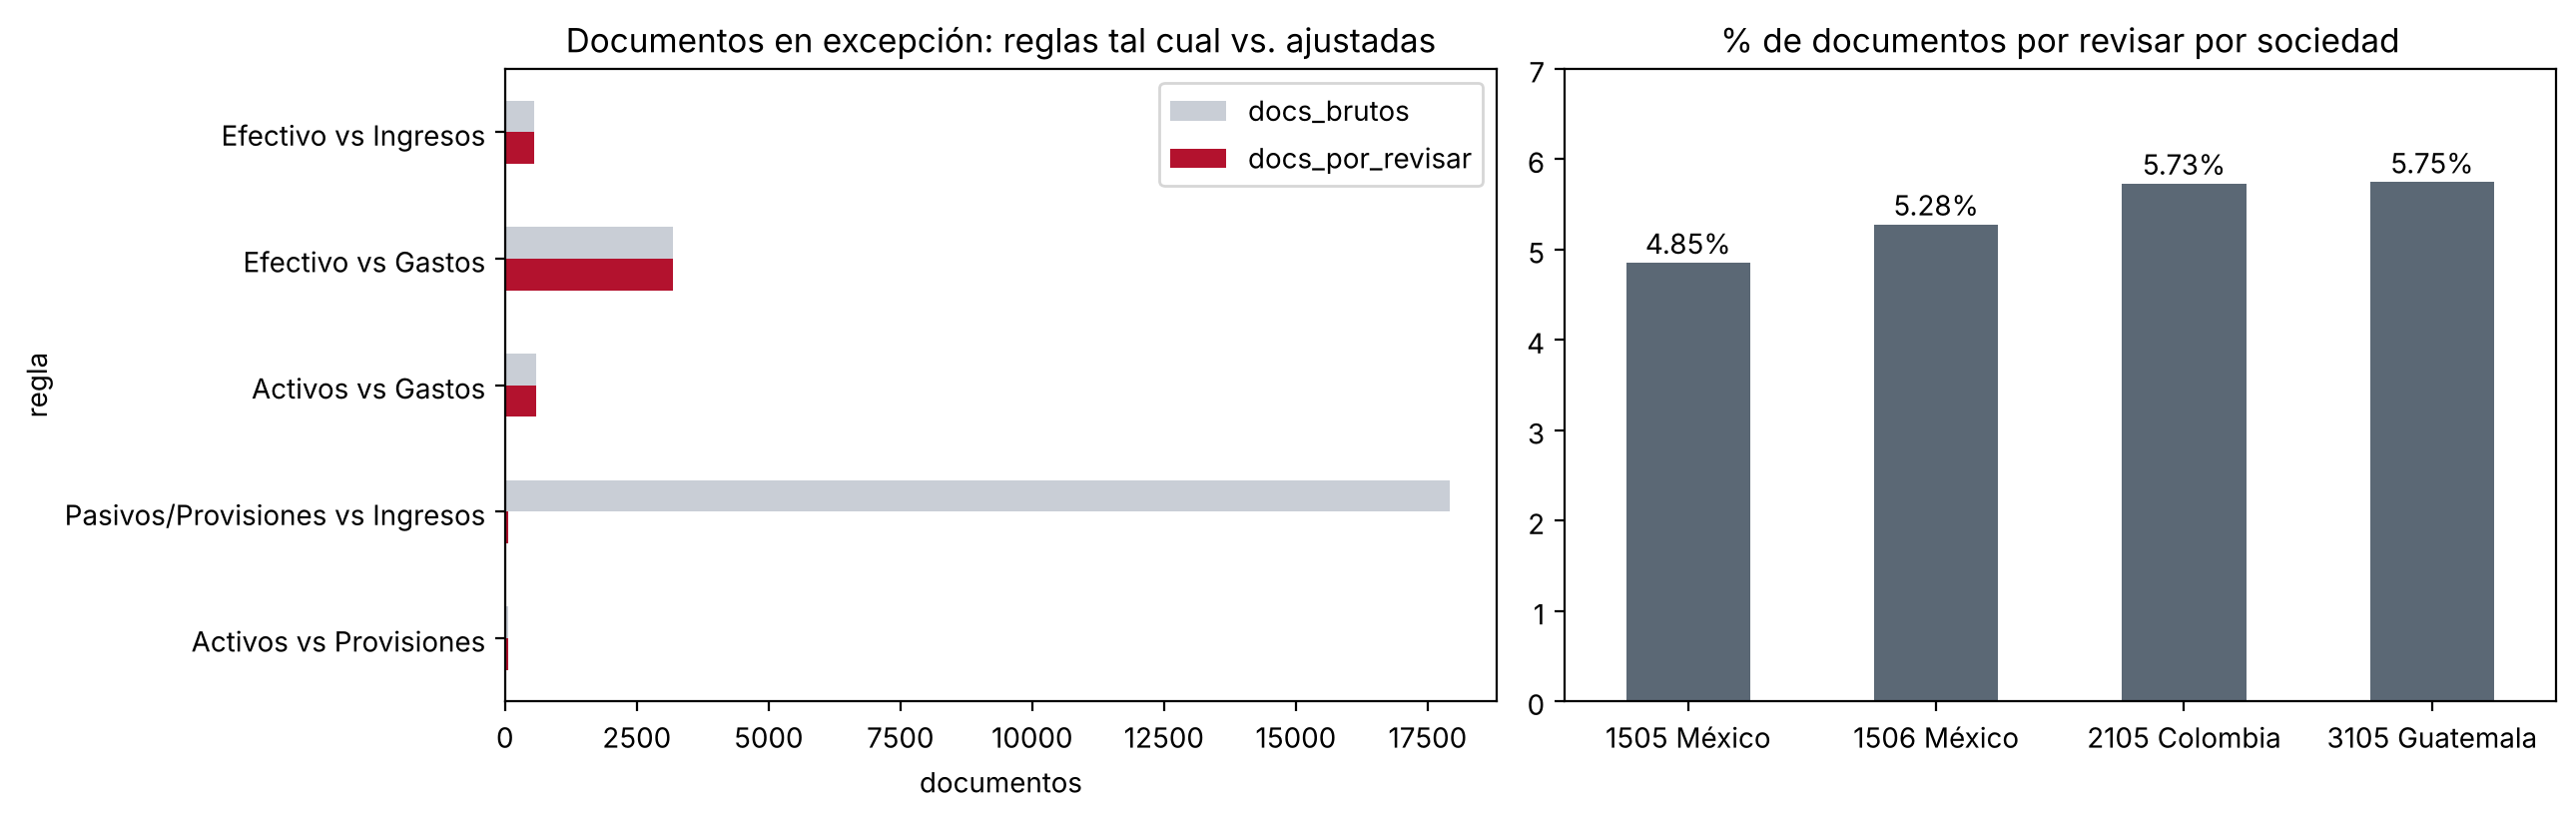

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
r = resumen.join(dim_regla.set_index("id_regla")[["regla"]]).set_index("regla")
r[["docs_brutos", "docs_por_revisar"]].plot.barh(ax=ax[0], color=["#C9CED6", "#B3122E"])
ax[0].invert_yaxis(); ax[0].set_title("Documentos en excepción: reglas tal cual vs. ajustadas"); ax[0].set_xlabel("documentos")
por_soc = docs.assign(revisar=docs.index.isin(rev)).groupby(["id_sociedad", "pais"]).revisar.mean().mul(100)
por_soc.index = [f"{s} {p}" for s, p in por_soc.index]
por_soc.plot.bar(ax=ax[1], color="#5B6875", rot=0)
for i, v in enumerate(por_soc): ax[1].text(i, v + 0.1, f"{v:.2f}%", ha="center")
ax[1].set_title("% de documentos por revisar por sociedad"); ax[1].set_ylim(0, 7)
plt.tight_layout(); plt.show()

### Señales de control interno

usuario_baja          26
usuario_generico      15
manual_fin_semana    394
creado_post_corte    204
alguna_senal         624
dtype: int64
Señales por mil documentos: 7.4
Rezago promedio: 0.33 días · documentos con rezago > 5 días: 993


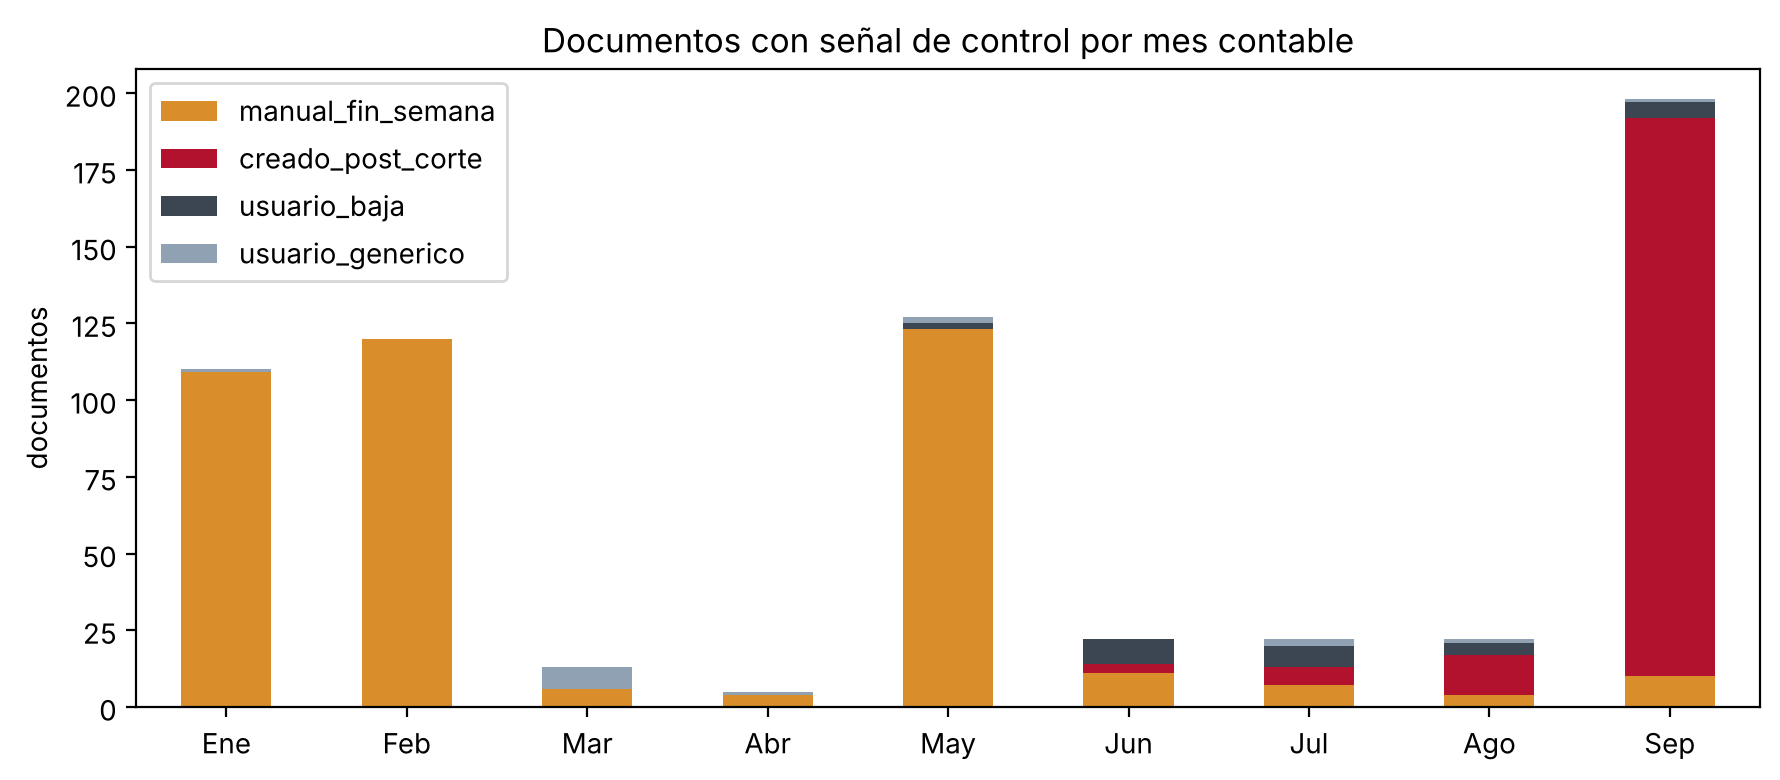

In [13]:
docs["alguna_senal"] = docs[["usuario_baja", "usuario_generico", "manual_fin_semana", "creado_post_corte"]].max(axis=1)
print(docs[["usuario_baja", "usuario_generico", "manual_fin_semana", "creado_post_corte", "alguna_senal"]].sum())
print(f"Señales por mil documentos: {docs.alguna_senal.mean()*1000:.1f}")
print(f"Rezago promedio: {docs.rezago_dias.mean():.2f} días · documentos con rezago > 5 días: {(docs.rezago_dias > 5).sum():,}")

senal_mes = docs.groupby("periodo")[["manual_fin_semana", "creado_post_corte", "usuario_baja", "usuario_generico"]].sum()
senal_mes.index = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep"]
senal_mes.plot.bar(stacked=True, figsize=(9, 4), rot=0, color=["#D98E2B", "#B3122E", "#3B4652", "#8FA1B3"],
                   title="Documentos con señal de control por mes contable")
plt.ylabel("documentos"); plt.tight_layout(); plt.show()

## Conclusiones y siguientes pasos

- Con el **100% de los documentos evaluados**, las reglas del socio tal cual marcan 22,308 documentos; el 80% viene de *Pasivos vs Ingresos* y son facturas de venta normales con IVA.
- Con la exclusión parametrizada quedan **4,449 documentos por revisar (5.24%)**. La **captura manual** es el 12% de ellos pero concentra el **80% del monto**.
- **Activos vs Provisiones** (54 documentos, todos manuales, 32 en Guatemala) es el primer caso para Auditoría.
- Las señales de control se concentran en el tiempo: capturas manuales en fin de semana en ene, feb y may; documentos creados después del corte en septiembre; un usuario dado de baja que siguió registrando.

**Siguientes pasos:** dashboard en Power BI sobre el modelo (Etapa 5), validar las reglas de negocio con Auditoría, y obtener las balanzas y los movimientos FAR e inversiones en proceso para probar los dos flujos pendientes.